<a href="https://colab.research.google.com/github/pauloricardodomingues21-byte/Tech-Challenge-Fase-1/blob/main/notebooks/eda_nps_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tech Challenge Fase 1 - EDA (Analise Exploratoria) do NPS

Rode as celulas na ordem. Cada grafico tambem e salvo em `reports/`.
O primeiro passo e subir o CSV.

In [1]:
from google.colab import files
up = files.upload()
NOME_CSV = list(up.keys())[0]
print('Arquivo carregado:', NOME_CSV)

Saving base_nps_teste.csv to base_nps_teste.csv
Arquivo carregado: base_nps_teste.csv


## Carga e visao geral

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('reports', exist_ok=True)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
ALVO = 'nps_score'

df = pd.read_csv(NOME_CSV).drop_duplicates()
df = df.dropna(subset=[ALVO])

# Classificacao padrao NPS: detrator 0-6, neutro 7-8, promotor 9-10
df['categoria_nps'] = pd.cut(df[ALVO], bins=[-1, 6, 8, 10],
                             labels=['Detrator', 'Neutro', 'Promotor'])
df['detrator'] = (df[ALVO] <= 6).astype(int)

print('Pedidos:', len(df), '| Colunas:', df.shape[1])
print('\nValores nulos por coluna (so as que tem):')
nulos = df.isna().sum()
print(nulos[nulos > 0] if (nulos > 0).any() else 'Nenhum')
df.describe().T.round(2)

Pedidos: 5000 | Colunas: 21

Valores nulos por coluna (so as que tem):
customer_age    60
order_value     60
dtype: int64


,count,mean,std,min,25%,50%,75%,max
customer_id,5000.0,2020.06,1145.55,3.00,1034.75,2003.00,3025.25,3998.00
order_id,5000.0,2500.50,1443.52,1.00,1250.75,2500.50,3750.25,5000.00
customer_age,4940.0,45.65,16.53,18.00,31.00,45.00,60.00,74.00
customer_tenure_months,5000.0,36.21,20.61,1.00,18.00,37.00,54.00,71.00
order_value,4940.0,271.93,153.40,8.99,157.47,242.46,355.76,1050.03
items_quantity,5000.0,4.00,1.99,1.00,2.00,4.00,6.00,7.00
discount_value,5000.0,23.69,16.83,0.25,11.30,19.62,31.83,138.64
payment_installments,5000.0,6.02,3.15,1.00,3.00,6.00,9.00,11.00
delivery_time_days,5000.0,12.89,6.63,2.00,7.00,13.00,19.00,24.00
delivery_delay_days,5000.0,1.20,1.09,0.00,0.00,1.00,2.00,7.00


## 1. Distribuicao do NPS

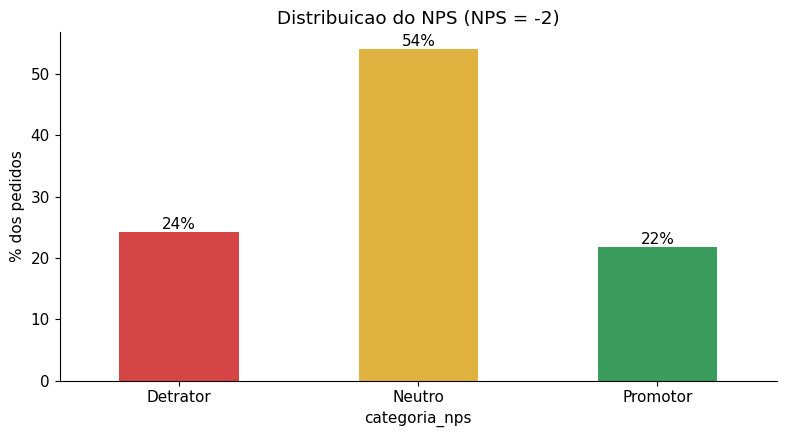

In [3]:
# 1) Como esta distribuido o NPS?
cont = df['categoria_nps'].value_counts(normalize=True).reindex(['Detrator','Neutro','Promotor'])
nps_final = (cont['Promotor'] - cont['Detrator']) * 100
cores = ['#d64545', '#e0b340', '#3a9d5d']
ax = (cont * 100).plot(kind='bar', color=cores, rot=0)
ax.set_ylabel('% dos pedidos')
ax.set_title(f'Distribuicao do NPS (NPS = {nps_final:.0f})')
for i, v in enumerate(cont * 100):
    ax.text(i, v + 0.5, f'{v:.0f}%', ha='center')
plt.tight_layout(); plt.savefig('reports/eda_1_distribuicao_nps.png', dpi=150); plt.show()

## 2. Onde a experiencia quebra?

In [4]:
# Funcao auxiliar: NPS medio e % de detratores por faixa de uma variavel
def nps_por_faixa(col, bins, labels, titulo, nome_arquivo):
    if col not in df.columns:
        print(f'Coluna {col} nao existe nesta base - pulando.'); return
    faixa = pd.cut(df[col], bins=bins, labels=labels)
    r = df.groupby(faixa, observed=True).agg(
        nps_medio=(ALVO, 'mean'), pct_detratores=('detrator', 'mean'),
        pedidos=(ALVO, 'size'))
    r['pct_detratores'] *= 100
    fig, ax = plt.subplots()
    ax.bar(r.index.astype(str), r['nps_medio'], color='#1f77b4')
    ax.set_ylabel('Nota media (0-10)'); ax.set_ylim(0, 10); ax.set_title(titulo)
    ax2 = ax.twinx()
    ax2.plot(r.index.astype(str), r['pct_detratores'], color='#d64545', marker='o')
    ax2.set_ylabel('% detratores (linha vermelha)'); ax2.set_ylim(0, 100)
    ax2.spines['right'].set_visible(True)
    plt.tight_layout(); plt.savefig(f'reports/{nome_arquivo}.png', dpi=150); plt.show()
    print(r.round(1).to_string(), '\n')
    return r

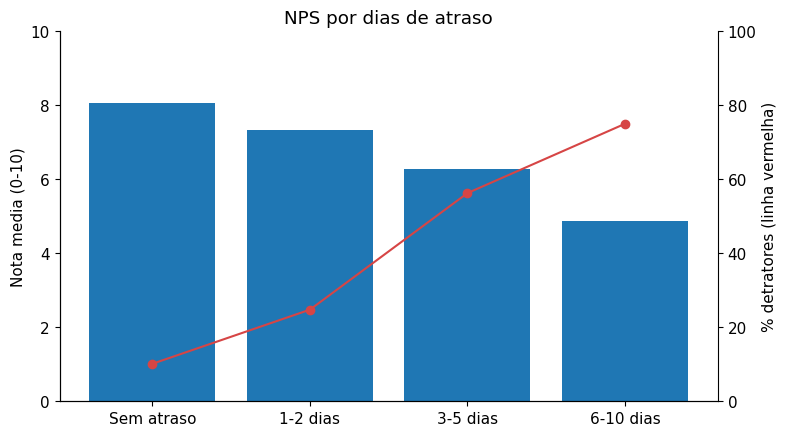

                     nps_medio  pct_detratores  pedidos
delivery_delay_days                                    
Sem atraso                 8.1            10.1     1499
1-2 dias                   7.3            24.8     2903
3-5 dias                   6.3            56.3      590
6-10 dias                  4.9            75.0        8 



In [5]:
# 2) PONTO DE RUPTURA: dias de atraso na entrega
r_atraso = nps_por_faixa('delivery_delay_days', [-1, 0, 2, 5, 10, 999],
    ['Sem atraso', '1-2 dias', '3-5 dias', '6-10 dias', '10+ dias'],
    'NPS por dias de atraso', 'eda_2_atraso')

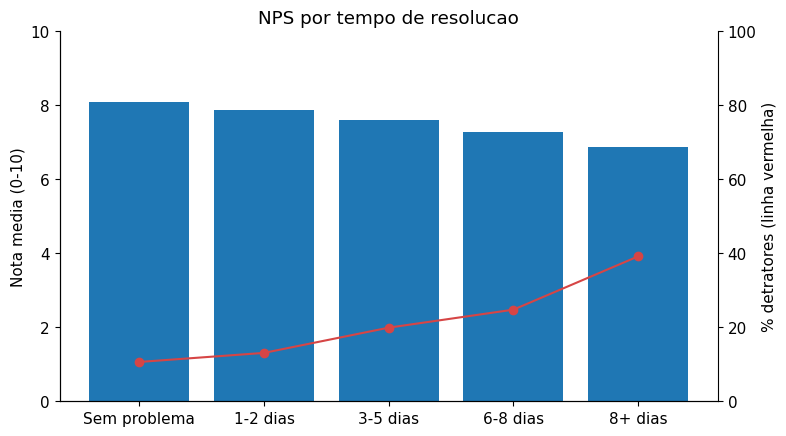

                      nps_medio  pct_detratores  pedidos
resolution_time_days                                    
Sem problema                8.1            10.6      414
1-2 dias                    7.9            13.1      841
3-5 dias                    7.6            19.9     1186
6-8 dias                    7.3            24.8     1272
8+ dias                     6.9            39.2     1287 



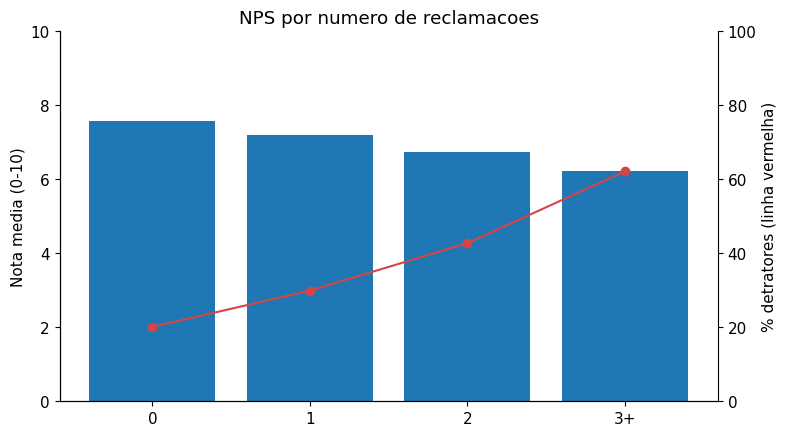

                  nps_medio  pct_detratores  pedidos
complaints_count                                    
0                       7.6            20.1     3352
1                       7.2            29.9     1377
2                       6.7            42.7      234
3+                      6.2            62.2       37 



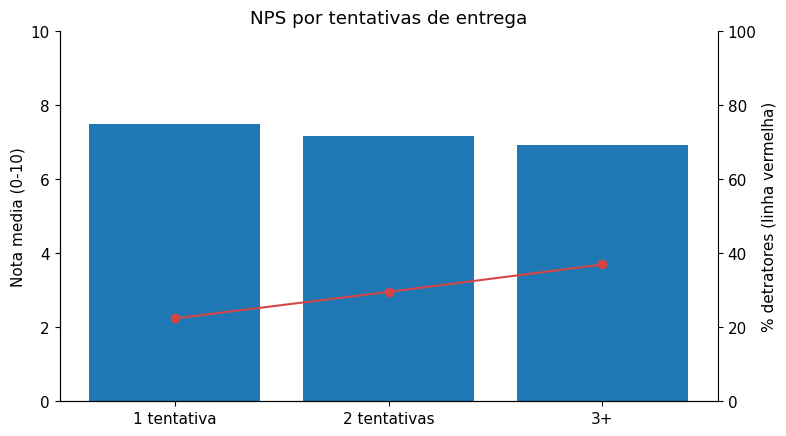

                   nps_medio  pct_detratores  pedidos
delivery_attempts                                    
1 tentativa              7.5            22.4     4015
2 tentativas             7.2            29.6      747
3+                       6.9            37.0      238 



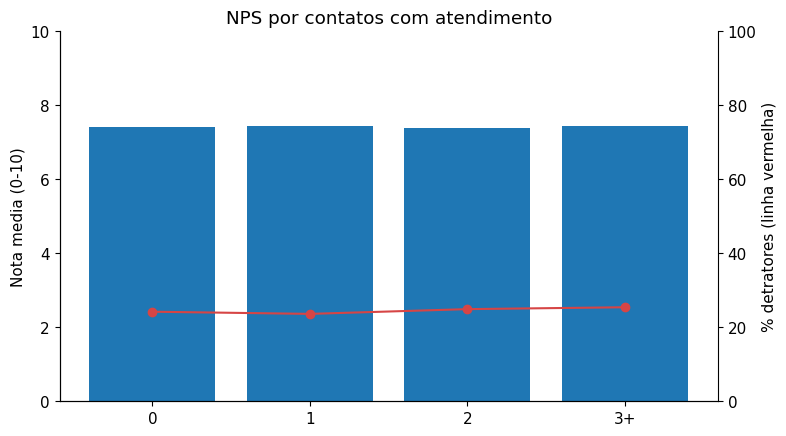

                           nps_medio  pct_detratores  pedidos
customer_service_contacts                                    
0                                7.4            24.2     2028
1                                7.4            23.6     1854
2                                7.4            24.9      819
3+                               7.4            25.4      299 



In [6]:
# 3) Tempo para resolver problemas
r_res = nps_por_faixa('resolution_time_days', [-1, 0, 2, 5, 8, 999],
    ['Sem problema', '1-2 dias', '3-5 dias', '6-8 dias', '8+ dias'],
    'NPS por tempo de resolucao', 'eda_3_resolucao')

# 4) Reclamacoes
r_recl = nps_por_faixa('complaints_count', [-1, 0, 1, 2, 999],
    ['0', '1', '2', '3+'], 'NPS por numero de reclamacoes', 'eda_4_reclamacoes')

# 5) Tentativas de entrega e contatos com atendimento
r_tent = nps_por_faixa('delivery_attempts', [0, 1, 2, 999],
    ['1 tentativa', '2 tentativas', '3+'], 'NPS por tentativas de entrega', 'eda_5_tentativas')
r_cont = nps_por_faixa('customer_service_contacts', [-1, 0, 1, 2, 999],
    ['0', '1', '2', '3+'], 'NPS por contatos com atendimento', 'eda_6_contatos')

## 3. Perfil do cliente

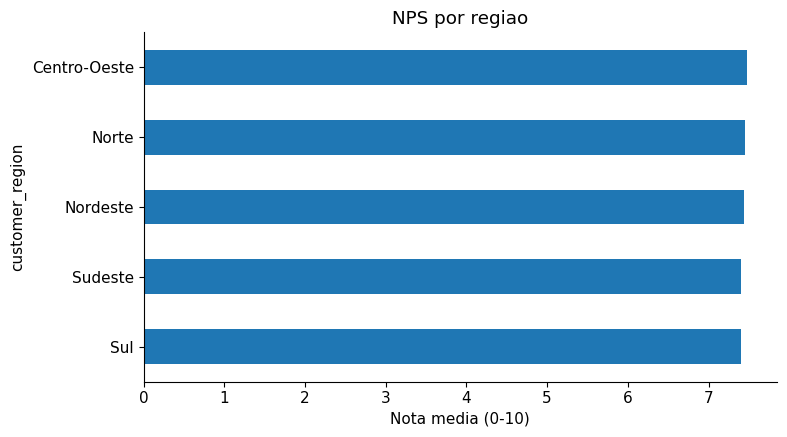

                 nps_medio  pct_detratores  pedidos
customer_region                                    
Sul                    7.4            23.9      937
Sudeste                7.4            25.0     2226
Nordeste               7.4            24.2      984
Norte                  7.4            22.3      354
Centro-Oeste           7.5            22.4      499 



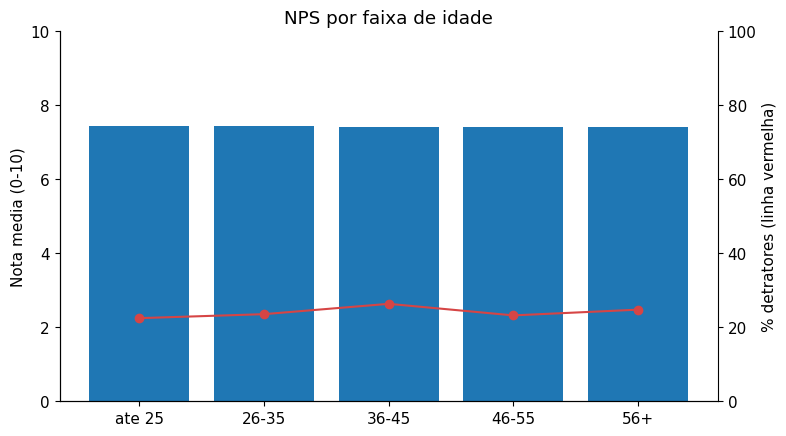

              nps_medio  pct_detratores  pedidos
customer_age                                    
ate 25              7.4            22.5      712
26-35               7.4            23.5      913
36-45               7.4            26.3      877
46-55               7.4            23.2      827
56+                 7.4            24.8     1611 



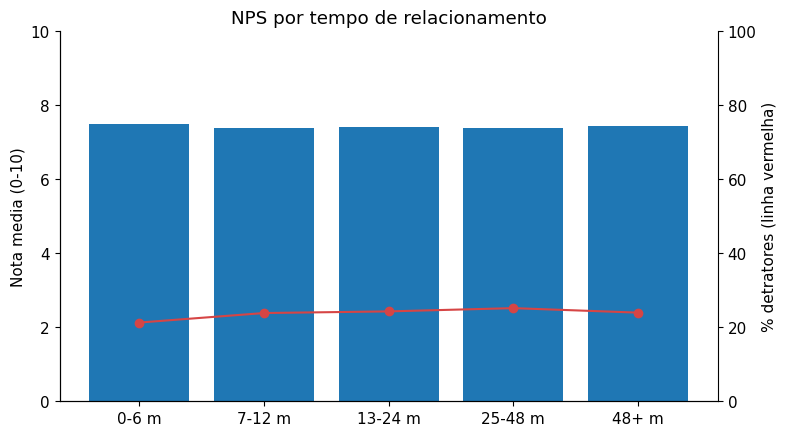

                        nps_medio  pct_detratores  pedidos
customer_tenure_months                                    
0-6 m                         7.5            21.3      437
7-12 m                        7.4            23.9      436
13-24 m                       7.4            24.3      782
25-48 m                       7.4            25.2     1684
48+ m                         7.4            24.0     1661 



In [7]:
# 6) Perfil do cliente: regiao, idade e tempo de relacionamento
if 'customer_region' in df.columns:
    reg = df.groupby('customer_region').agg(nps_medio=(ALVO, 'mean'),
        pct_detratores=('detrator', 'mean'), pedidos=(ALVO, 'size')).sort_values('nps_medio')
    reg['pct_detratores'] *= 100
    ax = reg['nps_medio'].plot(kind='barh', color='#1f77b4')
    ax.set_xlabel('Nota media (0-10)'); ax.set_title('NPS por regiao')
    plt.tight_layout(); plt.savefig('reports/eda_7_regiao.png', dpi=150); plt.show()
    print(reg.round(1).to_string(), '\n')

r_idade = nps_por_faixa('customer_age', [0, 25, 35, 45, 55, 200],
    ['ate 25', '26-35', '36-45', '46-55', '56+'], 'NPS por faixa de idade', 'eda_8_idade')
r_tempo = nps_por_faixa('customer_tenure_months', [-1, 6, 12, 24, 48, 999],
    ['0-6 m', '7-12 m', '13-24 m', '25-48 m', '48+ m'],
    'NPS por tempo de relacionamento', 'eda_9_relacionamento')

## 4. Visao geral e recompra

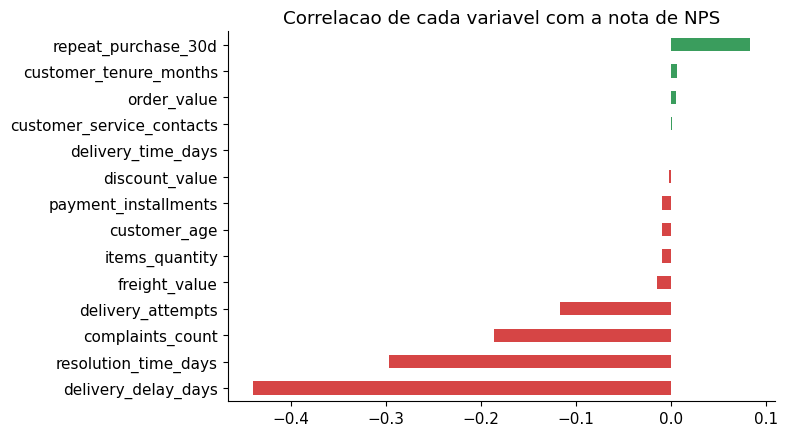

% de recompra em 30 dias por tipo de cliente:
categoria_nps
Detrator    27.1
Neutro      32.5
Promotor    36.8


In [8]:
# 7) Visao geral: quais variaveis andam junto com o NPS?
# (correlacao mostra associacao, NAO prova causa)
num = df.select_dtypes(include='number').drop(
    columns=['detrator', 'customer_id', 'order_id', 'csat_internal_score'], errors='ignore')
corr = num.corr()[ALVO].drop(ALVO).sort_values()
ax = corr.plot(kind='barh', color=['#d64545' if v < 0 else '#3a9d5d' for v in corr])
ax.set_title('Correlacao de cada variavel com a nota de NPS')
plt.tight_layout(); plt.savefig('reports/eda_10_correlacao.png', dpi=150); plt.show()

# 8) Recompra (so para a historia de negocio - NAO entra no modelo)
if 'repeat_purchase_30d' in df.columns:
    rec = df.groupby('categoria_nps', observed=True)['repeat_purchase_30d'].mean() * 100
    print('% de recompra em 30 dias por tipo de cliente:'); print(rec.round(1).to_string())

## 5. Resumo para os slides

In [9]:
# Resumo automatico para preencher os slides
print('=== RESUMO ===')
print(f'NPS geral: {nps_final:.0f} | Detratores: {cont["Detrator"]:.0%} | Promotores: {cont["Promotor"]:.0%}')
print('Variaveis mais associadas a nota baixa:')
print(corr.head(3).round(2).to_string())
if r_atraso is not None:
    print(f'\nSem atraso: {r_atraso["pct_detratores"].iloc[0]:.0f}% detratores | '
          f'Maior faixa de atraso: {r_atraso["pct_detratores"].iloc[-1]:.0f}% detratores')

=== RESUMO ===
NPS geral: -2 | Detratores: 24% | Promotores: 22%
Variaveis mais associadas a nota baixa:
delivery_delay_days    -0.44
resolution_time_days   -0.30
complaints_count       -0.19

Sem atraso: 10% detratores | Maior faixa de atraso: 75% detratores
